---
title: Week 5 Challenge 1 KEY
subtitle: DS 2023 | Communicating with Data
---

## Overview

In today's challenge, you will apply what you have learned about histograms.

Use the notebook **Histograms** as your guide.

Work in groups to perform the tasks.

When finished, submit a URL to this notebook in your GitHub repo to today's participation assignment.

## The data set

Today's dataset is the `diamonds` dataset available from Seaborn, originally associated with Hadley Wickham's R **ggplot2** package.

It contains physical measurements, gemological grades, and prices for nearly $54,000$ round diamonds.

Each row is an observation for a single diamond.

**Data dictionary**

| Variable | Data Type | Domain / Range | Description |
|---|---|---|---|
| carat | Continuous | 0.2 – 5.01 | Physical weight of the diamond. |
| cut | Categorical (Ordinal) | Fair, Good, Very Good, Premium, Ideal | Quality of the cut, lowest to highest. |
| color | Categorical (Ordinal) | J – D | Color grade, worst to best. |
| clarity | Categorical (Ordinal) | I1 – IF | Clarity grade, worst to best. |
| depth | Continuous | 43 – 79 | Total depth as a percentage of diameter. |
| table | Continuous | 43 – 95 | Width of the top facet as a percentage of diameter. |
| price | Integer | $326 – $18,823 | Retail price in US dollars. |

We will work mostly with `price` and `carat`, both of which are ratio measures and therefore good candidates for a histogram.

## Set Up

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
diamonds = sns.load_dataset('diamonds')
diamonds.info()
diamonds.head()

<class 'pandas.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   carat    53940 non-null  float64 
 1   cut      53940 non-null  category
 2   color    53940 non-null  category
 3   clarity  53940 non-null  category
 4   depth    53940 non-null  float64 
 5   table    53940 non-null  float64 
 6   price    53940 non-null  int64   
 7   x        53940 non-null  float64 
 8   y        53940 non-null  float64 
 9   z        53940 non-null  float64 
dtypes: category(3), float64(6), int64(1)
memory usage: 3.0 MB


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


## Tasks

### Task 1

Create a histogram of `price` using $30$ bins.

Describe the shape of the distribution in a sentence.

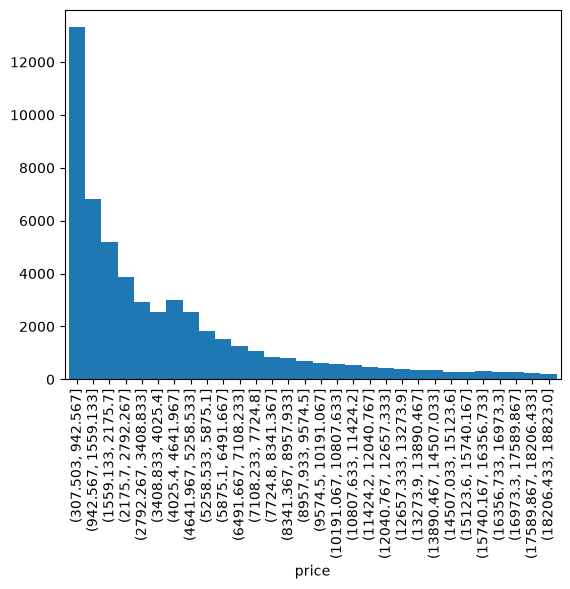

In [12]:
n_bins = 30
(
    pd.cut(diamonds.price, n_bins)
    .value_counts()
    .sort_index()
    .plot.bar(width=1)
)
plt.show()

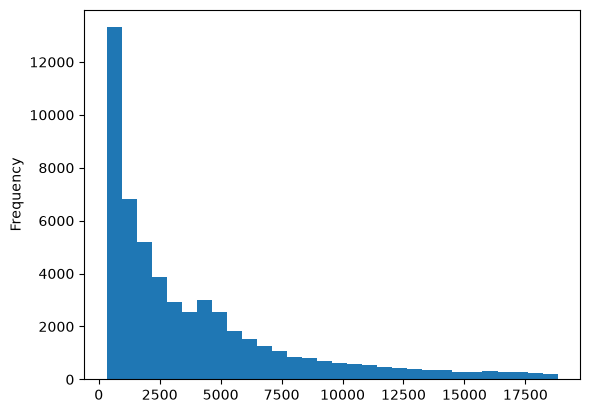

In [13]:
n_bins = 30

diamonds.price.plot.hist(bins=n_bins)
plt.show()

**Answer**: The shape of the distribution is right skewed.

### Task 2

Compute the mean and the median of `price`.

Why are they so far apart? Which one would you report, and why?

In [20]:
diamonds['price'].agg(['mean','median'])

mean      3932.799722
median    2401.000000
Name: price, dtype: float64

**Answer**: They are far apart because the shape of the distribution is heavily right skewed. The number I would report is the median because its value is the most typical and is not affected by extreme values.

### Task 3

Apply a log transformation to `price` and plot a histogram of the result.

Use $30$ bins.

Hint: Apply a log to the variable itself, _not_ to the plot by setting `logx` or `logy` to `True`.

Did the transformation help?

Hint: Use `.apply(np.log)`.

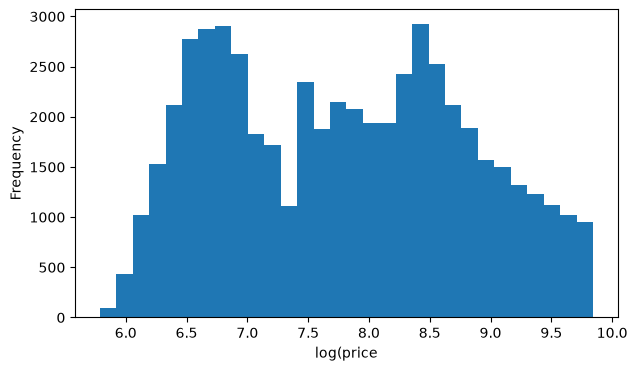

In [22]:
diamonds.price.apply(np.log).plot.hist(bins=30, figsize=(7,4))
plt.xlabel('log(price')
plt.show()

**Answer**: Yes, the skew falls from 1.62 to 0.12

### Task 4

Now plot a histogram of `carat` using $30$ bins.

Then plot the same variable using $200$ bins.

Restrict the data to diamonds of $2.1$ carats or less so that the tail does not compress the plot.

### Task 5

The $200$ bin version shows a pattern that the $30$ bin version only hints at.

Describe the pattern. What do you think causes it?

**Answer**:

### Task 6

Create a set of histograms of `price`, one for each value of `cut`, arranged as subplots.

Hint: first build a wide table in which each column holds the prices for one cut.

```python
price_by_cut = pd.DataFrame({
    cut: g.price.reset_index(drop=True)
    for cut, g in diamonds.groupby('cut', observed=True)
})
```

**Answer**:

### Bonus

The panels above are hard to compare because `Ideal` contains $21551$ diamonds and `Fair` contains only $1610$.

Redraw them so that each panel is comparable regardless of how many diamonds it contains.

Hint: `density=True`.

**Answer**: